## Задание 4. Работа с выбросами

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_csv('outliers_data.csv')

### Задание 1. Визуальная разведка

In [2]:
df.head()

,UserID,Age,Salary,PurchaseAmount,Category
0,U074,30,56311,53.96,Home
1,U019,33,63955,29.77,Home
2,U119,12,51816,31.21,Books
3,U079,19,76256,115.35,Electronics
4,U077,25,57684,77.78,Home


In [3]:
df[['Age', 'Salary', 'PurchaseAmount']].describe()

,Age,Salary,PurchaseAmount
count,150.000000,1.500000e+02,150.00000
mean,33.593333,1.649706e+05,147.21500
std,13.793344,9.137808e+05,500.05972
min,0.000000,1.428800e+04,-1000.00000
25%,26.000000,4.040700e+04,51.11000
50%,33.000000,5.189800e+04,97.31000
75%,41.500000,6.159775e+04,158.59250
max,145.000000,9.999999e+06,5000.00000


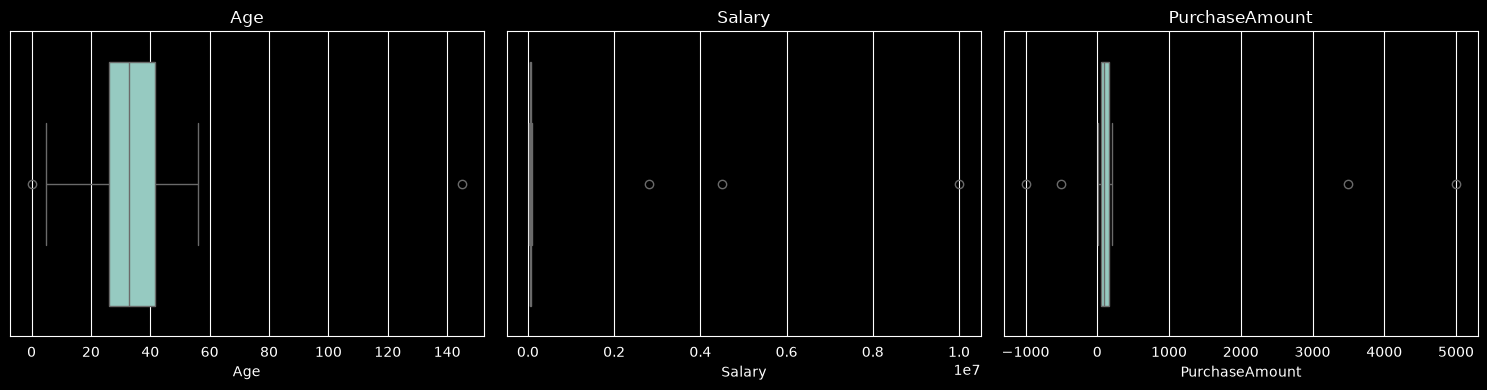

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ['Age', 'Salary', 'PurchaseAmount']):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

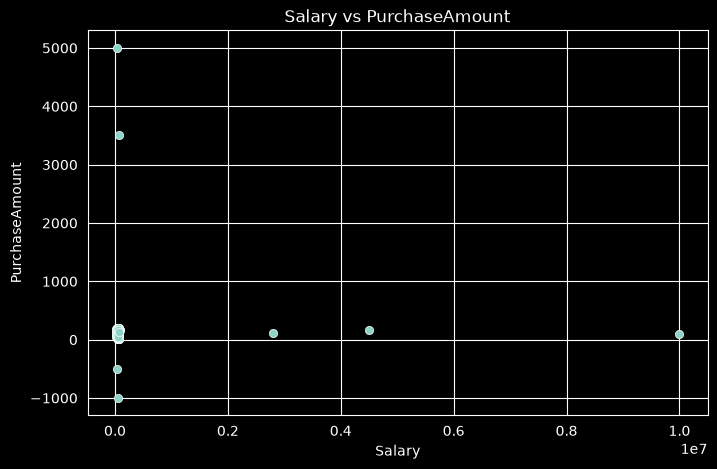

In [5]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x=df['Salary'], y=df['PurchaseAmount'])
plt.xlabel('Salary')
plt.ylabel('PurchaseAmount')
plt.title('Salary vs PurchaseAmount')
plt.show()

### Задание 2. Обнаружение методом IQR

In [6]:
Q1 = df['PurchaseAmount'].quantile(0.25)
Q3 = df['PurchaseAmount'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Q1 = {Q1:.2f}")
print(f"Q3 = {Q3:.2f}")
print(f"IQR = {IQR:.2f}")
print(f"Нижняя граница = {lower_bound:.2f}")
print(f"Верхняя граница = {upper_bound:.2f}")

Q1 = 51.11
Q3 = 158.59
IQR = 107.48
Нижняя граница = -110.11
Верхняя граница = 319.82


In [7]:
df['IsOutlier_IQR'] = (df['PurchaseAmount'] < lower_bound) | (df['PurchaseAmount'] > upper_bound)

print(f"Выбросов в PurchaseAmount: {df['IsOutlier_IQR'].sum()} из {len(df)} "
      f"({df['IsOutlier_IQR'].mean() * 100:.1f}%)")
df[df['IsOutlier_IQR']]

Выбросов в PurchaseAmount: 4 из 150 (2.7%)


,UserID,Age,Salary,PurchaseAmount,Category,IsOutlier_IQR
28,U046,50,62635,3500.0,Books,True
41,U086,27,48587,-1000.0,Electronics,True
107,U101,49,34262,5000.0,Home,True
144,U021,50,35747,-500.0,Home,True


### Задание 3. Обнаружение методом Z-score

In [8]:
df['Age_Z'] = np.abs(stats.zscore(df['Age']))

print(f"Среднее Age = {df['Age'].mean():.2f}, ст. отклонение = {df['Age'].std():.2f}")
print(f"Выбросов по Z-score (|Z| > 2.5): {(df['Age_Z'] > 2.5).sum()}")

df[df['Age_Z'] > 2.5][['UserID', 'Age', 'Age_Z']]

Среднее Age = 33.59, ст. отклонение = 13.79
Выбросов по Z-score (|Z| > 2.5): 1


,UserID,Age,Age_Z
29,U031,145,8.103901


In [9]:
small_ages = df[df['Age'] < 16][['UserID', 'Age', 'Age_Z']].sort_values('Age')
small_ages['Z_знаковый'] = (small_ages['Age'] - df['Age'].mean()) / df['Age'].std()
small_ages

,UserID,Age,Age_Z,Z_знаковый
18,U056,0,2.443633,-2.435474
44,U011,5,2.079925,-2.072981
2,U119,12,1.570734,-1.565489
91,U121,12,1.570734,-1.565489
92,U084,12,1.570734,-1.565489
138,U100,13,1.497992,-1.492991


### Задание 4. Обработка выбросов (Capping / Winsorization)

In [10]:
p99 = df['Salary'].quantile(0.99)

df['Salary_Capped'] = df['Salary'].clip(upper=p99)

print(f"99-й процентиль Salary = {p99:,.2f}")
print(f"Затронуто значений: {(df['Salary'] > p99).sum()} из {len(df)}")
print()
print(f"Средняя зарплата до = {df['Salary'].mean():>15,.2f}")
print(f"Средняя зарплата после = {df['Salary_Capped'].mean():>15,.2f}")
print(f"Медиана до = {df['Salary'].median():>15,.2f}")
print(f"Медиана после = {df['Salary_Capped'].median():>15,.2f}")
print()
print(f"Ст. отклонение до = {df['Salary'].std():>15,.2f}")
print(f"Ст. отклонение после = {df['Salary_Capped'].std():>15,.2f}")

99-й процентиль Salary = 3,667,000.00
Затронуто значений: 2 из 150

Средняя зарплата до =      164,970.57
Средняя зарплата после =      117,197.24
Медиана до =       51,898.00
Медиана после =       51,898.00

Ст. отклонение до =      913,780.76
Ст. отклонение после =      471,183.77


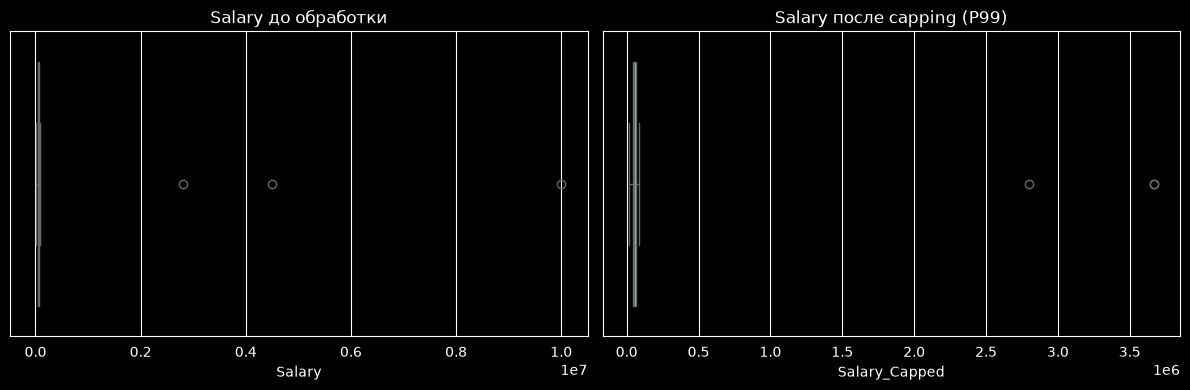

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df['Salary'], ax=axes[0])
axes[0].set_title('Salary до обработки')
sns.boxplot(x=df['Salary_Capped'], ax=axes[1])
axes[1].set_title('Salary после capping (P99)')
plt.tight_layout()
plt.show()

### Задание 5. Сравнительный анализ «до» и «после»

In [12]:
def iqr_mask(series, k=1.5):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    return (series < q1 - k * iqr) | (series > q3 + k * iqr)


mask_age = iqr_mask(df['Age'])
mask_salary = iqr_mask(df['Salary'])
mask_purchase = iqr_mask(df['PurchaseAmount'])

print(f"Выбросов по Age: {mask_age.sum()}")
print(f"Выбросов по Salary: {mask_salary.sum()}")
print(f"Выбросов по PurchaseAmount: {mask_purchase.sum()}")

outliers_any = mask_age | mask_salary | mask_purchase
print(f"Строк с выбросами хотя бы по одному признаку: {outliers_any.sum()}")

Выбросов по Age: 2
Выбросов по Salary: 3
Выбросов по PurchaseAmount: 4
Строк с выбросами хотя бы по одному признаку: 9


In [13]:
clean_df = df[~outliers_any].drop(columns=['IsOutlier_IQR', 'Age_Z', 'Salary_Capped'])

print(f"Было строк:  {len(df)}")
print(f"Стало строк: {len(clean_df)} (удалено {len(df) - len(clean_df)}, "
      f"{(len(df) - len(clean_df)) / len(df) * 100:.1f}%)")

Было строк:  150
Стало строк: 141 (удалено 9, 6.0%)


In [14]:
stats_compare = pd.concat(
    [df[['Age', 'Salary', 'PurchaseAmount']].describe(),
     clean_df[['Age', 'Salary', 'PurchaseAmount']].describe()],
    axis=1,
    keys=['До', 'После']
)
stats_compare

До                                    После                \
              Age        Salary PurchaseAmount         Age        Salary   
count  150.000000  1.500000e+02      150.00000  141.000000    141.000000   
mean    33.593333  1.649706e+05      147.21500   33.021277  50753.780142   
std     13.793344  9.137808e+05      500.05972    9.786629  14246.617941   
min      0.000000  1.428800e+04    -1000.00000    5.000000  14288.000000   
25%     26.000000  4.040700e+04       51.11000   26.000000  40458.000000   
50%     33.000000  5.189800e+04       97.31000   33.000000  51816.000000   
75%     41.500000  6.159775e+04      158.59250   40.000000  61331.000000   
max    145.000000  9.999999e+06     5000.00000   56.000000  85194.000000   

                      
      PurchaseAmount  
count      141.00000  
mean       102.48539  
std         56.42638  
min         10.59000  
25%         50.16000  
50%         97.11000  
75%        157.64000  
max        198.87000

In [15]:
for col in ['Age', 'Salary', 'PurchaseAmount']:
    d_mean = (clean_df[col].mean() - df[col].mean()) / df[col].mean() * 100
    d_med = (clean_df[col].median() - df[col].median()) / df[col].median() * 100
    print(f"{col:<16} среднее {d_mean:+7.2f}%   медиана {d_med:+7.2f}%   "
          f"std {df[col].std():.1f} -> {clean_df[col].std():.1f}")

Age              среднее   -1.70%   медиана   +0.00%   std 13.8 -> 9.8
Salary           среднее  -69.23%   медиана   -0.16%   std 913780.8 -> 14246.6
PurchaseAmount   среднее  -30.38%   медиана   -0.21%   std 500.1 -> 56.4


In [16]:
clean_df.to_csv('clean_outliers.csv', index=False)
clean_df.head()

,UserID,Age,Salary,PurchaseAmount,Category
0,U074,30,56311,53.96,Home
1,U019,33,63955,29.77,Home
2,U119,12,51816,31.21,Books
3,U079,19,76256,115.35,Electronics
4,U077,25,57684,77.78,Home
